# Evaluating Distributed Processing on Cloud


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Standard Hadoop Map Reduce implementation with different number of reducers

First try with datas passed trough chunks of 1 MB each.

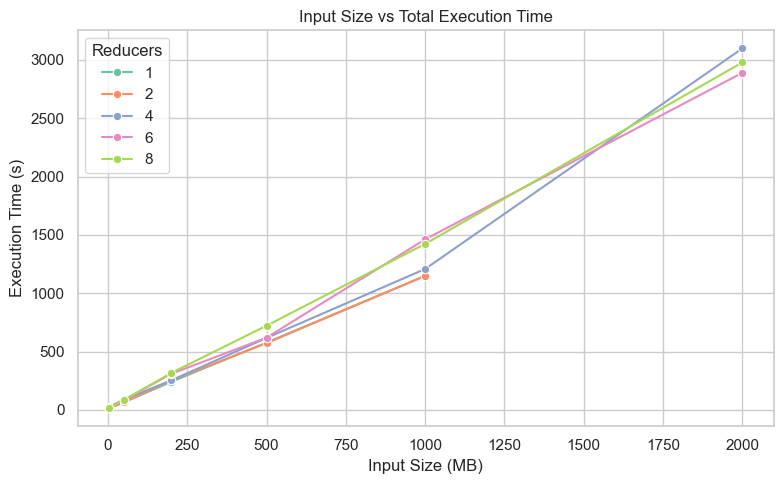

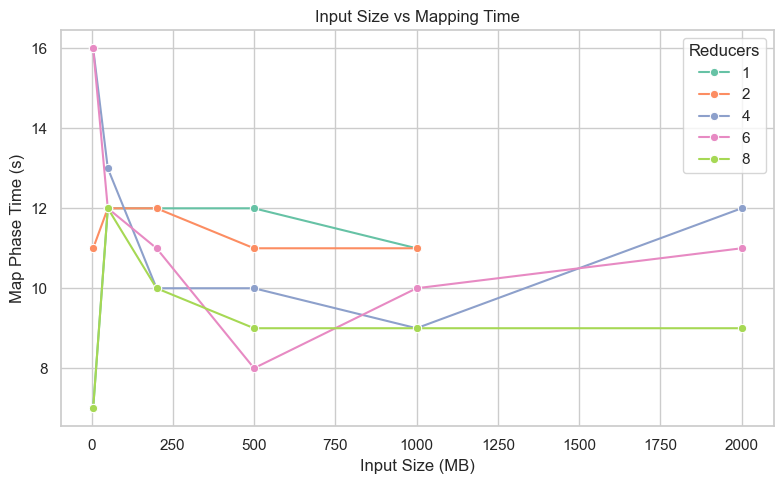

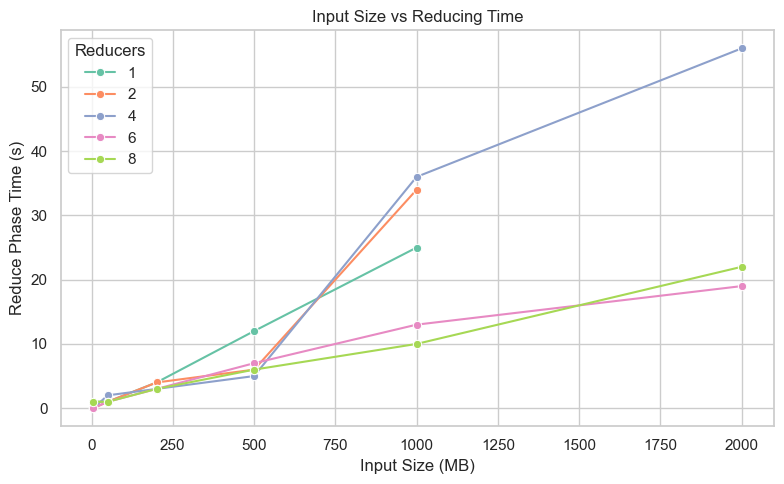

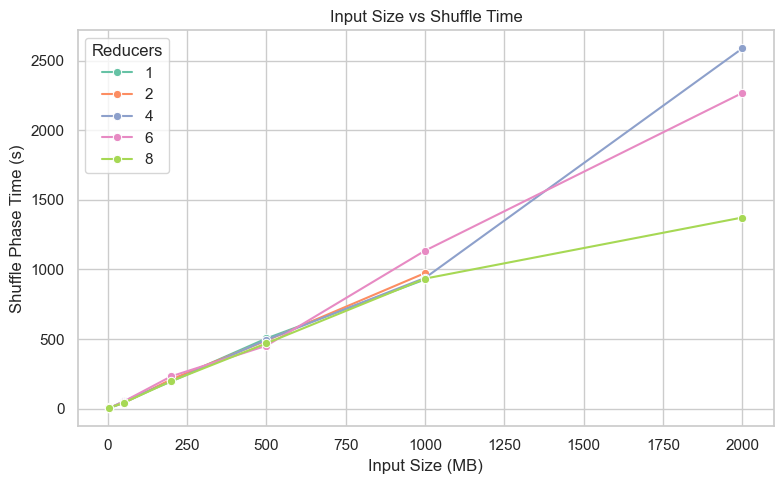

In [23]:
# Create your dataset
# input size: 5 MB, 50 MB, 200 MB, 500 MB, 1000 MB, 2000 MB
# reducers: 1, 2, 4, 6, 8
data = [
    {"input_size": 5, "execution_time": 15, "map_time": 7 , "reduce_time": 1 , "merge time": 0 , "shuffle_time": 4 , "reducers": 1},
    {"input_size": 50, "execution_time": 65 , "map_time": 12 , "reduce_time": 1,"merge time": 0, "shuffle_time": 41 , "reducers": 1},
    {"input_size": 200, "execution_time": 241, "map_time": 12 , "reduce_time": 4,"merge time": 1, "shuffle_time": 202, "reducers": 1},
    {"input_size": 500, "execution_time": 577, "map_time": 12 , "reduce_time": 12,"merge time": 5, "shuffle_time": 504 , "reducers": 1}, # con 1gb si blocca dopo 23m 52s.
    {"input_size": 1000, "execution_time": 1149 , "map_time": 11, "reduce_time": 25,"merge time": 16, "shuffle_time": 928 , "reducers": 1},
    # {"input_size": 2000, "execution_time": , "map_time":  , "reduce_time": ,"merge time": , "shuffle_time":  , "reducers": 1},
    {"input_size": 5, "execution_time": 18  , "map_time": 11, "reduce_time": 0,"merge time": 0, "shuffle_time": 8, "reducers": 2},
    {"input_size": 50, "execution_time": 65, "map_time": 12, "reduce_time": 1,"merge time": 0, "shuffle_time": 41, "reducers": 2},
    {"input_size": 200, "execution_time": 253, "map_time": 12, "reduce_time": 4,"merge time": 1, "shuffle_time": 210, "reducers": 2},
    {"input_size": 500, "execution_time": 573, "map_time": 11, "reduce_time": 6,"merge time": 3, "shuffle_time": 489, "reducers": 2},
    {"input_size": 1000, "execution_time": 1149, "map_time": 11, "reduce_time": 34,"merge time": 8, "shuffle_time": 974, "reducers": 2},
    # {"input_size": 2000, "execution_time":  , "map_time": , "reduce_time": ,"merge time":, "shuffle_time": , "reducers": 2},
    {"input_size": 5, "execution_time": 26, "map_time": 16, "reduce_time": 0 ,"merge time": 0, "shuffle_time": 3, "reducers": 4},
    {"input_size": 50, "execution_time": 88, "map_time": 13, "reduce_time": 2,"merge time": 0, "shuffle_time": 53, "reducers": 4},
    {"input_size": 200, "execution_time": 254, "map_time": 10 , "reduce_time": 3,"merge time": 0, "shuffle_time": 195, "reducers": 4},
    {"input_size": 500, "execution_time":  617, "map_time":10 , "reduce_time": 5,"merge time":1, "shuffle_time": 494, "reducers": 4},
    {"input_size": 1000, "execution_time": 1208, "map_time": 9, "reduce_time": 36, "merge time": 6, "shuffle_time": 939, "reducers": 4},
    {"input_size": 2000, "execution_time": 3099, "map_time": 12 , "reduce_time": 56 ,"merge time": 17, "shuffle_time": 2588, "reducers": 4},
    {"input_size": 5, "execution_time": 27 , "map_time": 16, "reduce_time": 0,"merge time": 0, "shuffle_time": 3, "reducers": 6},
    {"input_size": 50, "execution_time": 85 , "map_time": 12 , "reduce_time": 1 ,"merge time": 0, "shuffle_time": 51, "reducers": 6},
    {"input_size": 200, "execution_time": 310 , "map_time": 11, "reduce_time": 3,"merge time": 0, "shuffle_time": 232, "reducers": 6},
    {"input_size": 500, "execution_time": 619 , "map_time": 8, "reduce_time": 7,"merge time": 2, "shuffle_time": 452, "reducers": 6},
    {"input_size": 1000, "execution_time": 1462 , "map_time": 10 , "reduce_time": 13,"merge time": 4, "shuffle_time": 1135, "reducers": 6},
    {"input_size": 2000, "execution_time": 2890 , "map_time": 11, "reduce_time": 19,"merge time": 11, "shuffle_time": 2268, "reducers": 6},
    {"input_size": 5, "execution_time": 20 , "map_time": 7, "reduce_time": 1,"merge time": 0, "shuffle_time": 6, "reducers": 8},
    {"input_size": 50, "execution_time": 85 , "map_time": 12 , "reduce_time": 1,"merge time": 0, "shuffle_time": 42 , "reducers": 8},
    {"input_size": 200, "execution_time": 317  , "map_time": 10, "reduce_time": 3,"merge time": 0, "shuffle_time": 197, "reducers": 8},
    {"input_size": 500, "execution_time": 722 , "map_time": 9, "reduce_time": 6,"merge time": 1, "shuffle_time": 469, "reducers": 8},
    {"input_size": 1000, "execution_time": 1423 , "map_time": 9 , "reduce_time": 10 ,"merge time": 3, "shuffle_time": 934, "reducers": 8},
    {"input_size": 2000, "execution_time": 2979 , "map_time": 9, "reduce_time": 22,"merge time": 10, "shuffle_time": 1373, "reducers": 8}
]


# Convert to DataFrame
df = pd.DataFrame(data)

# Plot settings
plot_size = (8, 5)
sns.set(style="whitegrid")

# Plot 1: Total Execution Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="execution_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Total Execution Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Execution Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()

# Plot 2: Mapping Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="map_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Mapping Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Map Phase Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()

# Plot 3: Reducing Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="reduce_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Reducing Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Reduce Phase Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()

# Plot 4: Shuffle Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="shuffle_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Shuffle Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Shuffle Phase Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()


Real try passing the input trough chunks of variable dimensions. Hadoop seemed to have problem with having input formatted in small files.

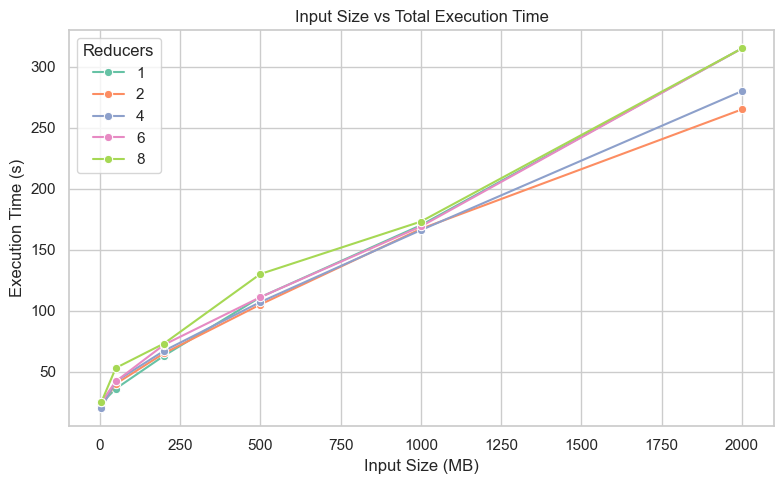

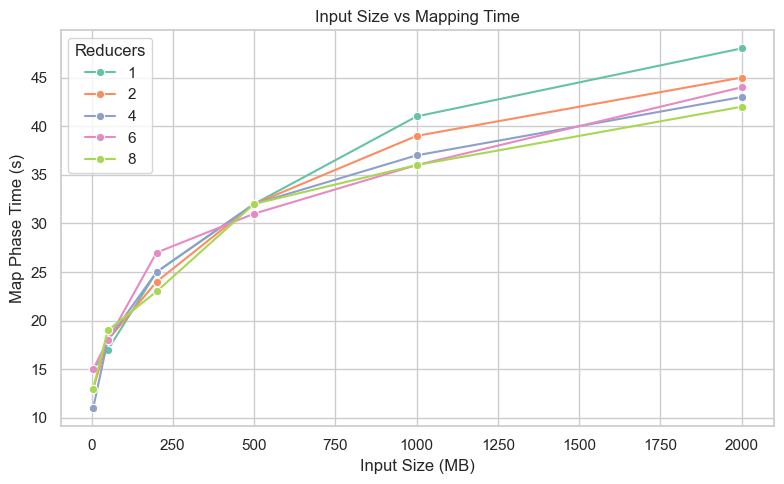

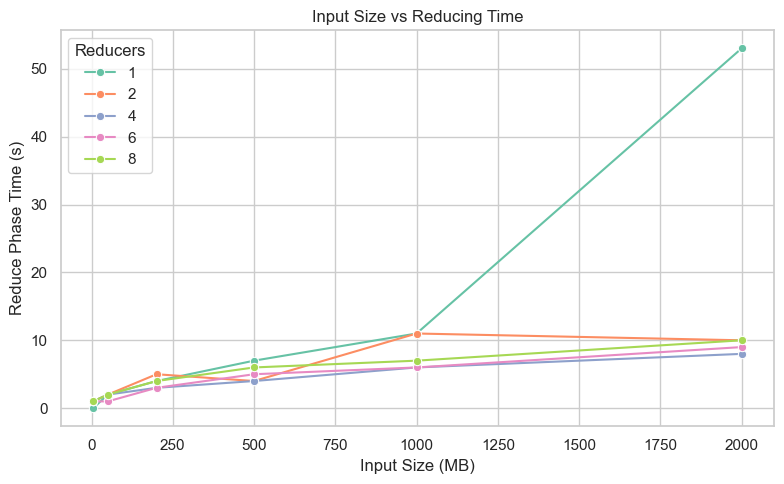

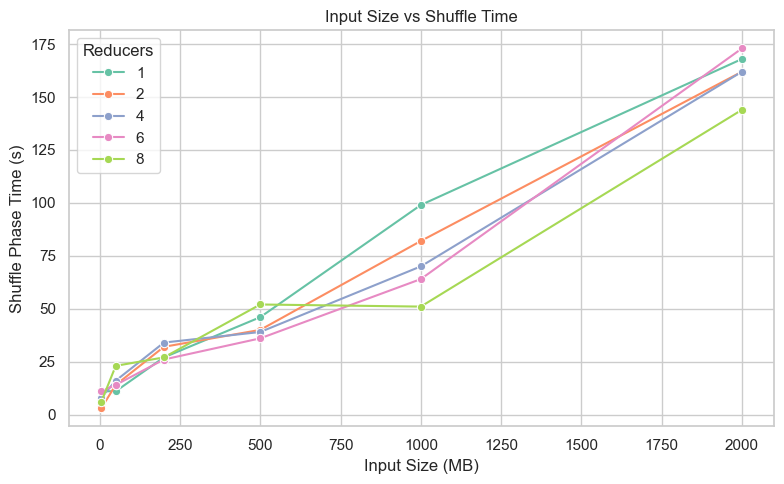

In [24]:
# Create your dataset
# input size: 5 MB, 50 MB, 200 MB, 500 MB, 1000 MB, 2000 MB
# reducers: 1, 2, 4, 6, 8
data = [
    {"input_size": 5, "execution_time": 24, "map_time": 15, "reduce_time": 0, "merge time": 0, "shuffle_time": 11, "reducers": 1},
    {"input_size": 50, "execution_time": 36 , "map_time": 17 , "reduce_time": 2,"merge time": 0, "shuffle_time": 11 , "reducers": 1},
    {"input_size": 200, "execution_time": 63, "map_time": 25 , "reduce_time": 4,"merge time": 1, "shuffle_time": 27, "reducers": 1},
    {"input_size": 500, "execution_time": 111, "map_time": 32 , "reduce_time": 7,"merge time": 1, "shuffle_time": 46, "reducers": 1},
    {"input_size": 1000, "execution_time": 170, "map_time": 41, "reduce_time": 11,"merge time": 2, "shuffle_time": 99, "reducers": 1},
    {"input_size": 2000, "execution_time": 315, "map_time": 48, "reduce_time": 53,"merge time": 5, "shuffle_time": 168, "reducers": 1},
    {"input_size": 5, "execution_time": 22, "map_time": 13, "reduce_time": 1,"merge time": 0, "shuffle_time": 3, "reducers": 2},
    {"input_size": 50, "execution_time": 40, "map_time": 18, "reduce_time": 2,"merge time": 0, "shuffle_time": 14, "reducers": 2},
    {"input_size": 200, "execution_time": 65, "map_time": 24, "reduce_time": 5,"merge time": 0, "shuffle_time": 32, "reducers": 2},
    {"input_size": 500, "execution_time": 105, "map_time": 32, "reduce_time": 4,"merge time": 0, "shuffle_time": 40, "reducers": 2},
    {"input_size": 1000, "execution_time": 167, "map_time": 39, "reduce_time": 11,"merge time": 1, "shuffle_time": 82, "reducers": 2},
    {"input_size": 2000, "execution_time": 265, "map_time": 45, "reduce_time": 10,"merge time": 2, "shuffle_time": 162, "reducers": 2},
    {"input_size": 5, "execution_time": 20, "map_time": 11, "reduce_time": 1 ,"merge time": 0, "shuffle_time": 8, "reducers": 4},
    {"input_size": 50, "execution_time": 42, "map_time": 18, "reduce_time": 2,"merge time": 0, "shuffle_time": 16, "reducers": 4},
    {"input_size": 200, "execution_time": 67, "map_time": 25 , "reduce_time": 3,"merge time": 0, "shuffle_time": 34, "reducers": 4},
    {"input_size": 500, "execution_time":  107, "map_time":32 , "reduce_time": 4,"merge time":0, "shuffle_time": 39, "reducers": 4},
    {"input_size": 1000, "execution_time": 166, "map_time": 37, "reduce_time": 6, "merge time": 0, "shuffle_time": 70, "reducers": 4},
    {"input_size": 2000, "execution_time": 280, "map_time": 43 , "reduce_time": 8 ,"merge time": 1, "shuffle_time": 162, "reducers": 4},
    {"input_size": 5, "execution_time": 25, "map_time": 15, "reduce_time": 1,"merge time": 0, "shuffle_time": 11, "reducers": 6},
    {"input_size": 50, "execution_time": 42, "map_time": 18 , "reduce_time": 1 ,"merge time": 0, "shuffle_time": 14, "reducers": 6},
    {"input_size": 200, "execution_time": 72, "map_time": 27, "reduce_time": 3,"merge time": 0, "shuffle_time": 26, "reducers": 6},
    {"input_size": 500, "execution_time": 111, "map_time": 31, "reduce_time": 5,"merge time": 0, "shuffle_time": 36, "reducers": 6},
    {"input_size": 1000, "execution_time": 169, "map_time": 36, "reduce_time": 6,"merge time": 0, "shuffle_time": 64, "reducers": 6},
    {"input_size": 2000, "execution_time": 315, "map_time": 44, "reduce_time": 9,"merge time": 1, "shuffle_time": 173, "reducers": 6},
    {"input_size": 5, "execution_time": 25, "map_time": 13, "reduce_time": 1,"merge time": 0, "shuffle_time": 6, "reducers": 8},
    {"input_size": 50, "execution_time": 53, "map_time": 19 , "reduce_time": 2,"merge time": 0, "shuffle_time": 23 , "reducers": 8},
    {"input_size": 200, "execution_time": 73 , "map_time": 23, "reduce_time": 4,"merge time": 0, "shuffle_time": 27, "reducers": 8},
    {"input_size": 500, "execution_time": 130, "map_time": 32, "reduce_time": 6,"merge time": 0, "shuffle_time": 52, "reducers": 8},
    {"input_size": 1000, "execution_time": 173 , "map_time": 36 , "reduce_time": 7 ,"merge time": 0, "shuffle_time": 51, "reducers": 8},
    {"input_size": 2000, "execution_time": 315 , "map_time": 42, "reduce_time": 10,"merge time": 1, "shuffle_time": 144, "reducers": 8}
]


# Convert to DataFrame
df = pd.DataFrame(data)

# Plot settings
plot_size = (8, 5)
sns.set(style="whitegrid")

# Plot 1: Total Execution Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="execution_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Total Execution Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Execution Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()

# Plot 2: Mapping Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="map_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Mapping Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Map Phase Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()

# Plot 3: Reducing Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="reduce_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Reducing Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Reduce Phase Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()

# Plot 4: Shuffle Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df, x="input_size", y="shuffle_time", hue="reducers", marker="o", palette="Set2")
plt.title("Input Size vs Shuffle Time")
plt.xlabel("Input Size (MB)")
plt.ylabel("Shuffle Phase Time (s)")
plt.tight_layout()
plt.legend(title="Reducers")
plt.show()

## Hadoop In-Mapper Combining vs Worst and Best Standard Hadoop Map Reduce

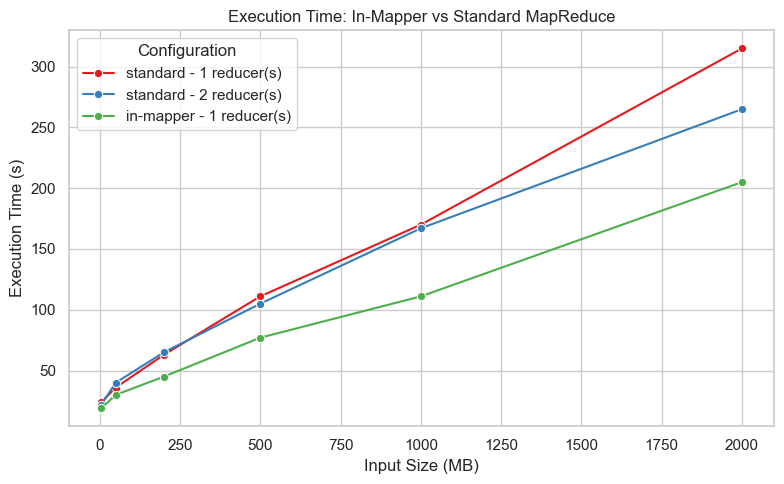

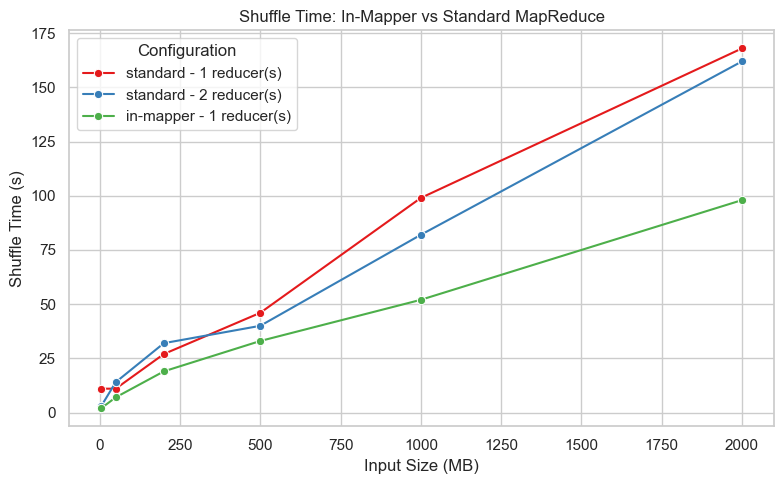

In [ ]:
in_mapper_data = [
    {"input_size": 5, "execution_time": 19, "shuffle_time": 2, "reducers": 1, "approach": "in-mapper"},
    {"input_size": 50, "execution_time": 30, "shuffle_time": 7, "reducers": 1, "approach": "in-mapper"},
    {"input_size": 200, "execution_time": 45, "shuffle_time": 19, "reducers": 1, "approach": "in-mapper"},
    {"input_size": 500, "execution_time": 77, "shuffle_time": 33, "reducers": 1, "approach": "in-mapper"},
    {"input_size": 1000, "execution_time": 111, "shuffle_time": 52, "reducers": 1, "approach": "in-mapper"},
    {"input_size": 2000, "execution_time": 205, "shuffle_time": 98, "reducers": 1, "approach": "in-mapper"},
]

# Label standard data
df["approach"] = "standard"

# Append in-mapper rows
df = pd.concat([df, pd.DataFrame(in_mapper_data)], ignore_index=True)
# Filter only the approaches and reducers we care about
df_filtered = df[
    ((df["approach"] == "in-mapper") & (df["reducers"] == 1)) |
    ((df["approach"] == "standard") & (df["reducers"].isin([1, 2])))
]

# Plot 1: Total Execution Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df_filtered, x="input_size", y="execution_time",
             hue=df_filtered.apply(lambda row: f"{row['approach']} - {row['reducers']} reducer(s)", axis=1),
             marker="o", palette="Set1")
plt.title("Execution Time: In-Mapper vs Standard MapReduce")
plt.xlabel("Input Size (MB)")
plt.ylabel("Execution Time (s)")
plt.tight_layout()
plt.legend(title="Configuration")
plt.show()

# Plot 4: Shuffle Time
plt.figure(figsize=plot_size)
sns.lineplot(data=df_filtered, x="input_size", y="shuffle_time",
             hue=df_filtered.apply(lambda row: f"{row['approach']} - {row['reducers']} reducer(s)", axis=1),
             marker="o", palette="Set1")
plt.title("Shuffle Time: In-Mapper vs Standard MapReduce")
plt.xlabel("Input Size (MB)")
plt.ylabel("Shuffle Time (s)")
plt.tight_layout()
plt.legend(title="Configuration")
plt.show()


## Best Standard Hadoop Map Reduce vs Spark

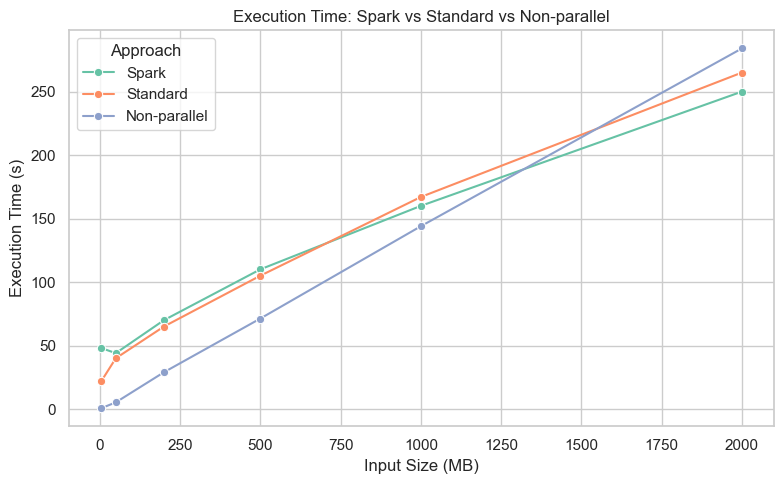

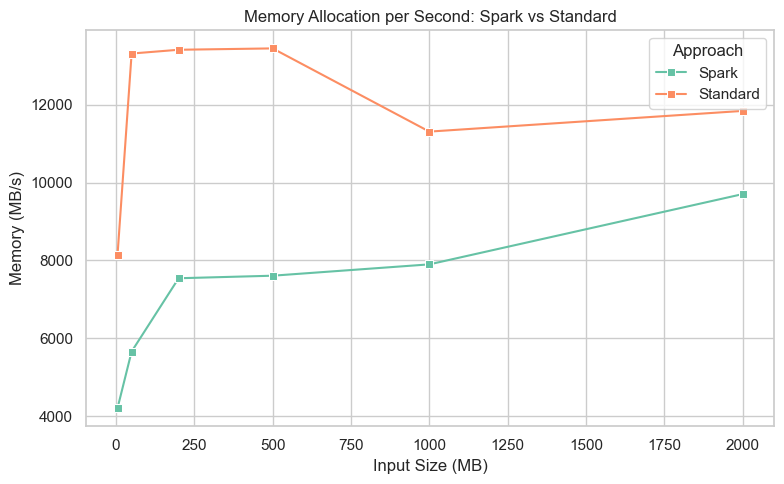

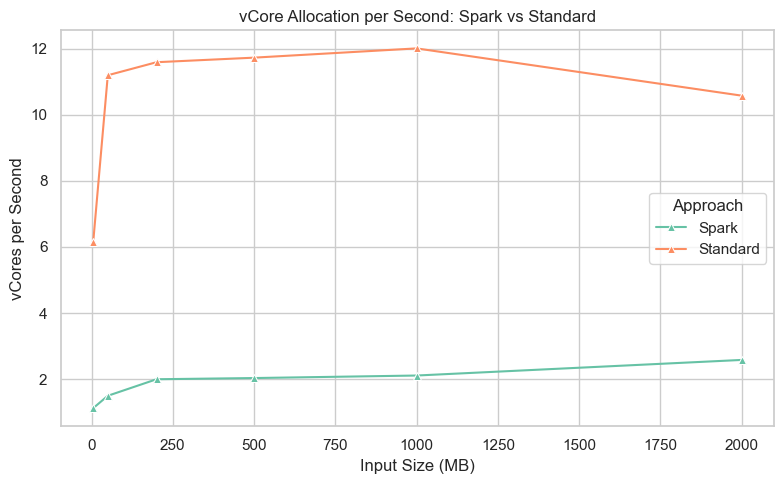

In [ ]:
spark_data = [
    {"input_size": 5, "execution_time": 48, "aggr_memory_allocation": 201888/48, "aggr_core_allocation": 54/48, "approach": "Spark"},
    {"input_size": 50, "execution_time": 44, "aggr_memory_allocation": 249074/44, "aggr_core_allocation": 66/44, "approach": "Spark"},
    {"input_size": 200, "execution_time": 70, "aggr_memory_allocation": 528020/70, "aggr_core_allocation": 140/70, "approach": "Spark"},
    {"input_size": 500, "execution_time": 110, "aggr_memory_allocation": 836930/110 , "aggr_core_allocation": 224/110, "approach": "Spark"},
    {"input_size": 1000, "execution_time": 160, "aggr_memory_allocation": 1263972/160, "aggr_core_allocation": 338/160, "approach": "Spark"},
    {"input_size": 2000, "execution_time": 250, "aggr_memory_allocation": 2426202/250, "aggr_core_allocation": 646/250, "approach": "Spark"},
]
standard_data = [
    {"input_size": 5, "execution_time": 22, "aggr_memory_allocation": 178993/22, "aggr_core_allocation": 135/22, "approach": "Standard"},
    {"input_size": 50, "execution_time": 40, "aggr_memory_allocation": 412746/31, "aggr_core_allocation": 347/31, "approach": "Standard"},
    {"input_size": 200, "execution_time": 65, "aggr_memory_allocation": 683978/51, "aggr_core_allocation": 591/51, "approach": "Standard"},
    {"input_size": 500, "execution_time": 105, "aggr_memory_allocation": 1277407/95, "aggr_core_allocation": 1114/95, "approach": "Standard"},
    {"input_size": 1000, "execution_time": 167, "aggr_memory_allocation": 1888660/167, "aggr_core_allocation": 2005/167, "approach": "Standard"},
    {"input_size": 2000, "execution_time": 265, "aggr_memory_allocation": 3137911/265, "aggr_core_allocation": 2803/265, "approach": "Standard"},
]
nonparallel_data = [
    {"input_size": 5, "execution_time": 0.68,  "approach": "Non-parallel"},
    {"input_size": 50, "execution_time": 5.27, "approach": "Non-parallel"},
    {"input_size": 200, "execution_time": 29,  "approach": "Non-parallel"},
    {"input_size": 500, "execution_time": 71.26,  "approach": "Non-parallel"},
    {"input_size": 1000, "execution_time": 143.98,  "approach": "Non-parallel"},
    {"input_size": 2000, "execution_time": 284.01,  "approach": "Non-parallel"},
]

# Combine Spark and Standard (for memory/core plots)
df_compare = pd.DataFrame(spark_data + standard_data)

# For execution time only, include all three approaches
df_exec = pd.DataFrame(spark_data + standard_data + nonparallel_data)

# Set seaborn style
sns.set(style="whitegrid", palette="Set2")

# Plot 1: Execution Time (includes Non-parallel)
plt.figure(figsize=(8, 5))
sns.lineplot(data=df_exec, x="input_size", y="execution_time", hue="approach", marker="o")
plt.title("Execution Time: Spark vs Standard vs Non-parallel")
plt.xlabel("Input Size (MB)")
plt.ylabel("Execution Time (s)")
plt.legend(title="Approach")
plt.tight_layout()
plt.show()

# Plot 2: Aggregated Memory Allocation per Second 
plt.figure(figsize=(8, 5))
sns.lineplot(data=df_compare, x="input_size", y="aggr_memory_allocation", hue="approach", marker="s")
plt.title("Memory Allocation per Second: Spark vs Standard")
plt.xlabel("Input Size (MB)")
plt.ylabel("Memory (MB/s)")
plt.legend(title="Approach")
plt.tight_layout()
plt.show()

# Plot 3: Aggregated Core Allocation per Second )
plt.figure(figsize=(8, 5))
sns.lineplot(data=df_compare, x="input_size", y="aggr_core_allocation", hue="approach", marker="^")
plt.title("vCore Allocation per Second: Spark vs Standard")
plt.xlabel("Input Size (MB)")
plt.ylabel("vCores per Second")
plt.legend(title="Approach")
plt.tight_layout()
plt.show()
